মোট ট্রেনিং ডেটা: 70টি, টেস্টিং ডেটা: 30টি

--- Classical SVM (RBF Kernel) ---
Accuracy (নির্ভুলতা): 96.67%
সময় লেগেছে: 0.0142 সেকেন্ড

কোয়ান্টাম কার্নেল ম্যাট্রিক্স হিসাব করা হচ্ছে (কিছুক্ষণ অপেক্ষা করুন)...

--- Quantum Kernel SVM ---
Accuracy (নির্ভুলতা): 76.67%
সময় লেগেছে: 9.3216 সেকেন্ড



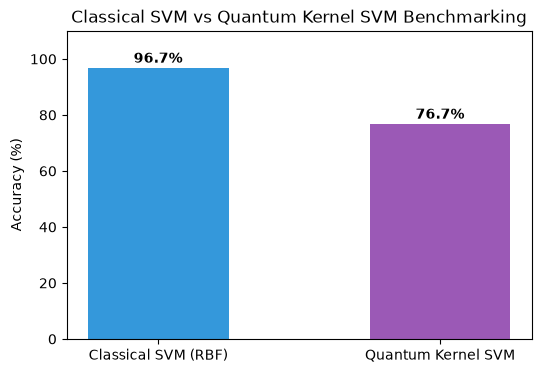

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# ১. Dataset তৈরি ও প্রস্তুত করা (Synthetic Non-Linear Dataset)
X, y = make_moons(n_samples=100, noise=0.15, random_state=42)

# ডেটাকে স্কেলিং করা (কোয়ান্টাম সার্কিটে দেওয়ার জন্য এটি জরুরি)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Training (70%) and Testing (30%) data split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

print(f"Total Training Data: {len(X_train)} points, Test Data: {len(X_test)} points\n")

# ==========================================
# ২. Classical SVM Benchmark (RBF Kernel)
# ==========================================
start_time_classical = time.time()

classical_svm = SVC(kernel='rbf')
classical_svm.fit(X_train, y_train)
y_pred_classical = classical_svm.predict(X_test)

classical_time = time.time() - start_time_classical
classical_acc = accuracy_score(y_test, y_pred_classical) * 100

print(f"--- Classical SVM (RBF Kernel) ---")
print(f"Accuracy (নির্ভুলতা): {classical_acc:.2f}%")
print(f"সময় লেগেছে: {classical_time:.4f} সেকেন্ড\n")

# ==========================================
# ৩. Quantum Kernel SVM বেঞ্চমার্কিং
# ==========================================
n_qubits = 2  # যেহেতু আমাদের ডেটাতে ২টি ফিচার আছে
dev = qml.device("default.qubit", wires=n_qubits)

# কোয়ান্টাম ফিচার ম্যাপ (Quantum Feature Map)
def feature_map(x):
    qml.AngleEmbedding(x, wires=range(n_qubits), rotation='Y')
    qml.CNOT(wires=[0, 1])  # কিউবিটগুলোর মধ্যে এন্ট্যাঙ্গলমেন্ট তৈরি
    qml.AngleEmbedding(x, wires=range(n_qubits), rotation='Z')

# দুটি ডেটা পয়েন্টের মধ্যে কোয়ান্টাম মিল (Kernel Value) বের করার সার্কিট
@qml.qnode(dev)
def kernel_circuit(x1, x2):
    feature_map(x1)
    qml.adjoint(feature_map)(x2)
    return qml.probs(wires=range(n_qubits))

# সম্পূর্ণ কার্নেল ম্যাট্রিক্স তৈরি করার ফাংশন
def compute_quantum_kernel_matrix(A, B):
    matrix = np.zeros((len(A), len(B)))
    for i, x1 in enumerate(A):
        for j, x2 in enumerate(B):
            # |00> স্টেটে ফিরে আসার সম্ভাবনাই হলো কার্নেল ভ্যালু
            matrix[i, j] = kernel_circuit(x1, x2)[0]
    return matrix

start_time_quantum = time.time()

print("কোয়ান্টাম কার্নেল ম্যাট্রিক্স হিসাব করা হচ্ছে (কিছুক্ষণ অপেক্ষা করুন)...")
kernel_train = compute_quantum_kernel_matrix(X_train, X_train)
kernel_test = compute_quantum_kernel_matrix(X_test, X_train)

# প্রাক-গণনাকৃত (Precomputed) কোয়ান্টাম কার্নেল দিয়ে SVM ট্রেন করা
quantum_svm = SVC(kernel='precomputed')
quantum_svm.fit(kernel_train, y_train)
y_pred_quantum = quantum_svm.predict(kernel_test)

quantum_time = time.time() - start_time_quantum
quantum_acc = accuracy_score(y_test, y_pred_quantum) * 100

print(f"\n--- Quantum Kernel SVM ---")
print(f"Accuracy (নির্ভুলতা): {quantum_acc:.2f}%")
print(f"সময় লেগেছে: {quantum_time:.4f} সেকেন্ড\n")

# ==========================================
# ৪. ফলাফলের তুলনামূলক গ্রাফ (Visualization)
# ==========================================
models = ['Classical SVM (RBF)', 'Quantum Kernel SVM']
accuracies = [classical_acc, quantum_acc]

plt.figure(figsize=(6, 4))
bars = plt.bar(models, accuracies, color=['#3498db', '#9b59b6'], width=0.5)
plt.ylim(0, 110)
plt.ylabel('Accuracy (%)')
plt.title('Classical SVM vs Quantum Kernel SVM Benchmarking')

# বারের ওপরে পার্সেন্টেজ লেখা দেখানো
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.1f}%", ha='center', fontweight='bold')

plt.show()


In [1]:
import pennylane as qml

# Create a quantum device with one qubit
dev = qml.device("default.qubit", wires=1)

# Create a quantum circuit
@qml.qnode(dev)
def circuit():

    # Apply Hadamard gate
    qml.Hadamard(wires=0)

    # Measure the qubit
    return qml.probs(wires=0)

# Execute the circuit
print(circuit())

[0.5 0.5]
